# Spam Detection with Machine Learning

**Goal:** build a Natural Language Processing (NLP) classifier that tells **spam** messages apart from legitimate (**ham**) ones.

**Data:** the classic *SMS Spam Collection* (5,572 text messages, each labelled `ham` or `spam`), which is the dataset suggested in the task brief. The method is exactly the same for emails: only the text changes.

**Tools:** Python, pandas, scikit-learn (TF-IDF, Naive Bayes, Logistic Regression), `re` and NLTK's Porter stemmer.

**What this notebook does, in order**

1. Load the data and check the class distribution
2. Clean the text (lowercase, punctuation, stopwords, stemming)
3. Turn text into numbers with TF-IDF
4. Split into train and test sets
5. Train two classifiers (plus a third for comparison)
6. Evaluate them (accuracy, precision, recall, F1, confusion matrix)
7. Discuss why recall matters for spam detection
8. Bonus: word clouds of spam and ham words
9. Save the best model for the website

In [ ]:
# Libraries we need
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.stem import PorterStemmer
from wordcloud import WordCloud

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42   # fixed so the results are the same every time you run it

## 1. Load the data and check the class distribution

The file uses an older text encoding (`latin-1`), so we tell pandas about it. It also has three extra, almost empty columns left over from when it was created. We only need the first two: the label (`v1`) and the message text (`v2`).

In [ ]:
# Read the CSV and keep only the label and the message
raw = pd.read_csv("data/spam.csv", encoding="latin-1")
df = raw[["v1", "v2"]].rename(columns={"v1": "label", "v2": "message"})

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


,count,percentage (%)
label,,
ham,4825,86.59
spam,747,13.41


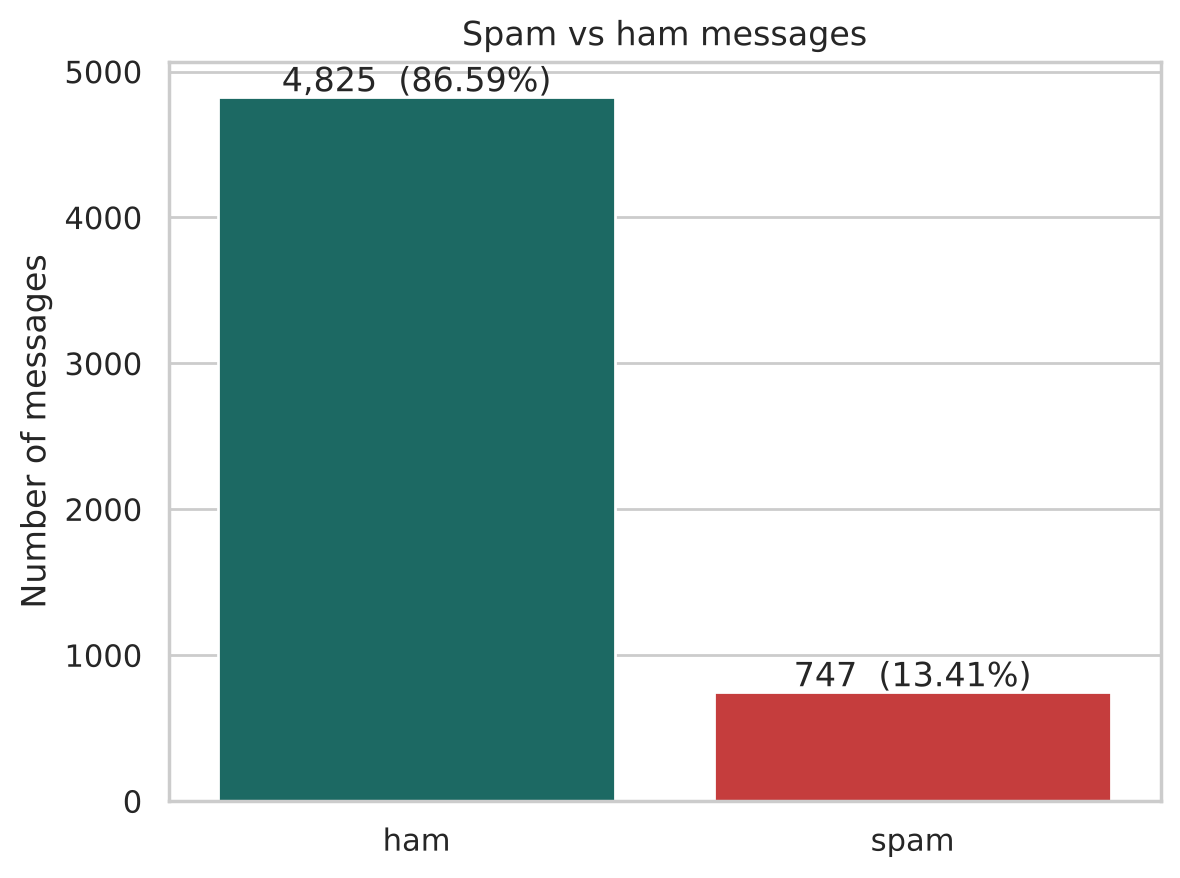

In [ ]:
# Class distribution: how many spam vs ham messages, and what percentage?
counts = df["label"].value_counts()
percent = df["label"].value_counts(normalize=True).mul(100).round(2)
distribution = pd.DataFrame({"count": counts, "percentage (%)": percent})
display(distribution)

# A quick picture of the same thing
ax = sns.barplot(x=counts.index, y=counts.values, hue=counts.index,
                 palette={"ham": "#0f766e", "spam": "#dc2626"}, legend=False)
ax.set_title("Spam vs ham messages")
ax.set_xlabel("")
ax.set_ylabel("Number of messages")
for i, v in enumerate(counts.values):
    ax.text(i, v + 40, f"{v:,}  ({percent.iloc[i]}%)", ha="center")
plt.show()

**What we see:** the data is **imbalanced**. Only about 13% of the messages are spam. That is realistic (most messages people receive are legitimate), but it has a consequence: a lazy model that called *everything* ham would already be about 87% accurate while catching zero spam. So **accuracy alone can fool us**, and we need precision, recall and F1 too.

### Quick data checks
Before cleaning the text, two things are worth checking: missing values and duplicates.

In [ ]:
print("Missing messages:", df["message"].isna().sum())
print("Missing labels:  ", df["label"].isna().sum())

duplicates = df.duplicated().sum()
print("Exact duplicate rows:", duplicates)

# Which class do the duplicates come from?
print(df[df.duplicated()]["label"].value_counts())

Missing messages: 0
Missing labels:   0
Exact duplicate rows: 403
label
ham     309
spam     94
Name: count, dtype: int64


There are 403 exact duplicates. If we left them in, the same message could end up in both the training set and the test set, and the model would look better than it really is because it has already "seen the answer". So we remove them (keeping the first copy of each).

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)

print("Rows after removing duplicates:", len(df))
print(df["label"].value_counts())
print((df["label"].value_counts(normalize=True) * 100).round(2).astype(str) + " %")

Rows after removing duplicates: 5169
label
ham     4516
spam     653
Name: count, dtype: int64
label
ham     87.37 %
spam    12.63 %
Name: proportion, dtype: str


## 2. Text preprocessing

Raw messages are messy: capital letters, punctuation, filler words like "the" and "and", and many forms of the same word ("win", "wins", "winning"). The cleaning pipeline below simplifies all of that:

| Step | What it does | Example |
|---|---|---|
| **Lowercase** | "FREE" and "free" become the same word | `FREE` → `free` |
| **Remove punctuation** | Strips symbols so they don't split words apart | `prize!!` → `prize` |
| **Remove stopwords** | Drops very common words that carry little meaning | `you`, `the`, `to` |
| **Stemming** (optional, used here) | Cuts words down to their root | `winning` → `win` |

Numbers are **kept** on purpose: spam is full of prices, short codes and phone numbers, which are useful clues.

In [ ]:
import re
from nltk.stem import PorterStemmer

# A standard English stopword list (the same idea as NLTK's list), written out
# here so nobody has to download anything. Apostrophes are removed before the
# check, so "don't" is looked up as "dont".
STOPWORDS = frozenset("""
i me my myself we our ours ourselves you your yours yourself yourselves he him
his himself she her hers herself it its itself they them their theirs themselves
what which who whom this that these those am is are was were be been being have
has had having do does did doing a an the and but if or because as until while of
at by for with about against between into through during before after above below
to from up down in out on off over under again further then once here there when
where why how all any both each few more most other some such no nor not only own
same so than too very s t can will just don should now
im ive id ill youre youve youd youll hes shes thats theyre theyve theyd theyll
weve wed dont doesnt didnt isnt arent wasnt werent hasnt havent hadnt wont wouldnt
shouldnt couldnt cant mustnt neednt aint
""".split())

_stemmer = PorterStemmer()


def tokenize(text):
    """Return a list of (original_word, stem) pairs for the useful words in text."""
    text = str(text).lower()                      # 1. lowercase
    # don't -> dont. The data also holds curly quotes and, because of its old
    # encoding, garbled characters that stand for the same apostrophe: "\x92"
    # and "\x89\u00fb\u00f7" (written in lowercase, because we lowercased above).
    for apostrophe in ("'", "\u2019", "\u2018", "\x91", "\x92", "\x89\u00fb\u00f7"):
        text = text.replace(apostrophe, "")
    text = re.sub(r"[^a-z0-9\s]", " ", text)      # 2. remove punctuation
    pairs = []
    for word in text.split():
        if word in STOPWORDS or len(word) < 2:    # 3. remove stopwords
            continue
        pairs.append((word, _stemmer.stem(word)))  # 4. stem (winning -> win)
    return pairs


def clean_text(text):
    """Return the cleaned message as one string of stems."""
    return " ".join(stem for _, stem in tokenize(text))

In [ ]:
# See the cleaning in action on a real spam message
example = df[df["label"] == "spam"]["message"].iloc[0]
print("BEFORE:", example)
print("AFTER: ", clean_text(example))

BEFORE: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
AFTER:  free entri wkli comp win fa cup final tkt 21st may 2005 text fa 87121 receiv entri question std txt rate cs appli 08452810075over18


In [ ]:
# Clean every message and store the result in a new column
df["clean"] = df["message"].apply(clean_text)

# A few messages might be empty after cleaning (e.g. only stopwords). Check:
print("Messages that became empty:", (df["clean"].str.strip() == "").sum())
df[["label", "message", "clean"]].head()

Messages that became empty: 12


,label,message,clean
0,ham,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi great world l...
1,ham,Ok lar... Joking wif u oni...,ok lar joke wif oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entri wkli comp win fa cup final tkt 21st...
3,ham,U dun say so early hor... U c already then say...,dun say earli hor alreadi say
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though


## 3. Feature extraction with TF-IDF

Machine learning models need numbers, not words, so we convert each message into a list of numbers using **TF-IDF**.

**What TF-IDF measures**

TF-IDF stands for **Term Frequency × Inverse Document Frequency**. It gives every word in a message a score that answers: *"how important is this word for this message?"*

- **Term Frequency (TF)** is how often the word appears in *this* message. A word used several times is probably relevant to it.
- **Inverse Document Frequency (IDF)** is how *rare* the word is across *all* messages. A word that appears in nearly every message (like "call" or "get") tells us little, so it is scaled down. A rare word (like "jackpot") tells us a lot, so it is scaled up.

Multiplying the two means a word scores high when it is **frequent in this message but rare overall**. Words like "claim" or "prize" end up with big scores in spam messages, while everyday chat words score low. Each message's scores are then rescaled to a common length so long and short messages can be compared fairly.

Let's see it on a tiny example before applying it to the real data:

In [ ]:
tiny = ["win a free prize now", "are we still meeting for lunch", "free prize free entry"]
demo = TfidfVectorizer()
scores = demo.fit_transform(tiny)
pd.DataFrame(scores.toarray(), columns=demo.get_feature_names_out(),
             index=["msg 1", "msg 2", "msg 3"]).round(2)

,are,entry,for,free,lunch,meeting,now,prize,still,we,win
msg 1,0.00,0.00,0.00,0.43,0.00,0.00,0.56,0.43,0.00,0.00,0.56
msg 2,0.41,0.00,0.41,0.00,0.41,0.41,0.00,0.00,0.41,0.41,0.00
msg 3,0.00,0.51,0.00,0.77,0.00,0.00,0.00,0.39,0.00,0.00,0.00


In message 3, "free" appears twice, so it gets the highest score. Words that show up in only one message (like "lunch") get a higher IDF than words shared between messages.

We will fit the real TF-IDF vectoriser right after splitting the data, in the next section. There is a good reason for that order, explained there.

## 4. Train / test split

We keep **20%** of the messages hidden as a test set. The models never see them during training, so the test results tell us how the models will behave on new messages.

Two details matter here:

- `stratify=y` keeps the spam/ham ratio the same in both sets. With only ~13% spam, a random split could otherwise give an unrepresentative test set.
- We fit the TF-IDF vectoriser on the **training messages only**. If it learned word rarity from the test messages too, information from the test set would leak into training and the scores would be slightly too optimistic.

In [ ]:
# Labels as numbers: spam = 1, ham = 0
y = (df["label"] == "spam").astype(int)
X_text = df["clean"]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Training messages: {len(X_train_text):,}")
print(f"Test messages:     {len(X_test_text):,}")
print(f"Spam share  train: {y_train.mean():.1%}   test: {y_test.mean():.1%}")

Training messages: 4,135
Test messages:     1,034
Spam share  train: 12.6%   test: 12.7%


In [ ]:
# Fit TF-IDF on the training text only, then apply it to both sets.
# min_df=2 ignores words that appear in just one training message (mostly typos
# and one-off phone numbers), which keeps the vocabulary smaller and cleaner.
tfidf = TfidfVectorizer(min_df=2)
X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Vocabulary size:", len(tfidf.vocabulary_), "words")
print("Training matrix shape:", X_train.shape)

Vocabulary size: 2788 words
Training matrix shape: (4135, 2788)


## 5. Train the classifiers

We train **three** models, which is one more than the brief asks for:

1. **Multinomial Naive Bayes** (the industry standard for text). It is very fast and works well with word counts and TF-IDF scores.
2. **Logistic Regression** (the required alternative). A simple, reliable linear model.
3. **Linear SVM** (bonus comparison). Often the strongest of the classic text models.

In [ ]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Linear SVM": LinearSVC(random_state=RANDOM_STATE),
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)               # learn from the training messages
    predictions[name] = model.predict(X_test)  # predict the hidden test messages
    print("Trained:", name)

Trained: Multinomial Naive Bayes
Trained: Logistic Regression
Trained: Linear SVM


## 6. Evaluation

For each model we report:

- **Accuracy:** the share of all messages classified correctly
- **Precision:** of the messages we *called* spam, how many really were spam
- **Recall:** of the messages that *really are* spam, how many we caught
- **F1-score:** a single number that balances precision and recall
- **Confusion matrix:** the full count of right and wrong calls (rows are the truth, columns are the prediction)

In [ ]:
rows = []
for name, pred in predictions.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
    })

results = pd.DataFrame(rows).set_index("Model")
results.round(4)

,Accuracy,Precision,Recall,F1-score
Model,,,,
Multinomial Naive Bayes,0.9739,0.9815,0.8092,0.8870
Logistic Regression,0.9681,0.9900,0.7557,0.8571
Linear SVM,0.9845,0.9915,0.8855,0.9355


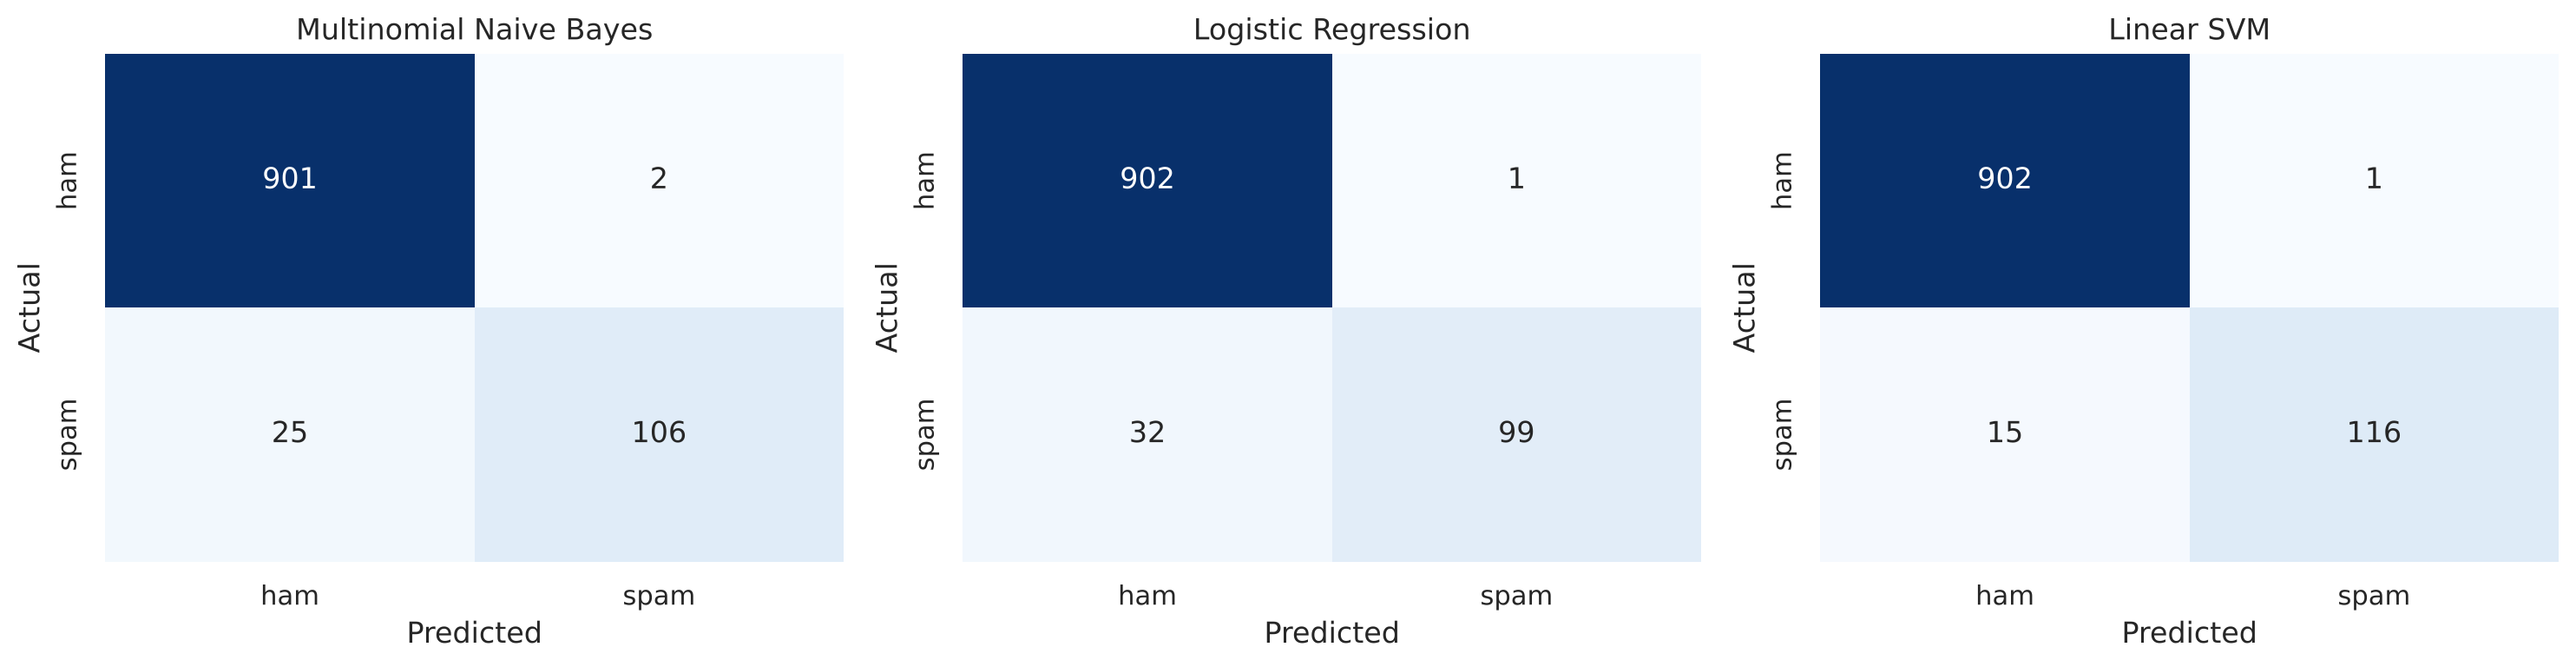

In [ ]:
# Confusion matrices side by side
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [ ]:
# The detailed per-class report for each model
for name, pred in predictions.items():
    print("=" * 60)
    print(name)
    print(classification_report(y_test, pred, target_names=["ham", "spam"], digits=3))

Multinomial Naive Bayes
              precision    recall  f1-score   support

         ham      0.973     0.998     0.985       903
        spam      0.981     0.809     0.887       131

    accuracy                          0.974      1034
   macro avg      0.977     0.903     0.936      1034
weighted avg      0.974     0.974     0.973      1034

Logistic Regression
              precision    recall  f1-score   support

         ham      0.966     0.999     0.982       903
        spam      0.990     0.756     0.857       131

    accuracy                          0.968      1034
   macro avg      0.978     0.877     0.920      1034
weighted avg      0.969     0.968     0.966      1034

Linear SVM
              precision    recall  f1-score   support

         ham      0.984     0.999     0.991       903
        spam      0.991     0.885     0.935       131

    accuracy                          0.985      1034
   macro avg      0.988     0.942     0.963      1034
weighted avg      0

In [ ]:
# In plain words: what happened to the spam messages for each model?
for name, pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"{name}:")
    print(f"   spam caught: {tp} of {tp + fn}   |   spam missed: {fn}   |   good messages wrongly flagged: {fp}")

Multinomial Naive Bayes:
   spam caught: 106 of 131   |   spam missed: 25   |   good messages wrongly flagged: 2
Logistic Regression:
   spam caught: 99 of 131   |   spam missed: 32   |   good messages wrongly flagged: 1
Linear SVM:
   spam caught: 116 of 131   |   spam missed: 15   |   good messages wrongly flagged: 1


**Reading the results:** all three models are accurate (97-98%), but accuracy hides the real difference. They almost never flag a good message by mistake (1 or 2 out of about 900), so the gap is in **how much spam each one lets through**. The **Linear SVM** is the clear winner: it misses 15 spam messages, against 25 for Naive Bayes and 32 for Logistic Regression, and it has the best F1-score.

Notice that Logistic Regression has higher precision than Naive Bayes but the lowest recall of the three. It is cautious: it only calls something spam when it is very sure, so it lets more spam slip past.

## 7. Discussion: why is recall particularly important for spam detection?

**Recall answers one question: of all the spam that arrives, how much do we actually catch?**

Every spam message the model misses (a *false negative*) lands in someone's inbox. That is more than an annoyance:

- Spam is how **scams and phishing** reach people. A single missed "your account is locked, click here" message can cost someone their money or their login details.
- Missed spam **builds up**. A filter that lets 1 in 5 spam messages through still leaves users facing a steady stream, and they quickly stop trusting it.
- Spam is rare (about 13% of messages here), so a model can post a very high **accuracy** while still missing a large share of the spam. Our own results show it: Logistic Regression scores 96.8% accuracy, yet its recall is only about 76%, so roughly 1 in 4 spam messages gets through. Recall looks at the spam class directly, so it can't be hidden by the huge number of easy ham messages.

**But recall is not the whole story.** If we pushed recall to 100% by flagging everything, every legitimate message would end up in the spam folder, which is a different kind of failure: a *false positive* (a job offer or a bank notice that never gets read). That is what **precision** protects against.

So in practice the goal is **high recall while keeping precision high**, and **F1** summarises that balance. For spam filtering, many teams care a little more about not losing real mail, so they accept a few missed spam messages. Which side you favour depends on the cost of each mistake, and you can move that balance by changing the decision threshold.

## 8. (Bonus) Word clouds

A word cloud shows which words are most common in each class: the bigger the word, the more often it appears. We use the cleaned (stemmed) text, so words appear in their root form, like `claim` and `prize`.

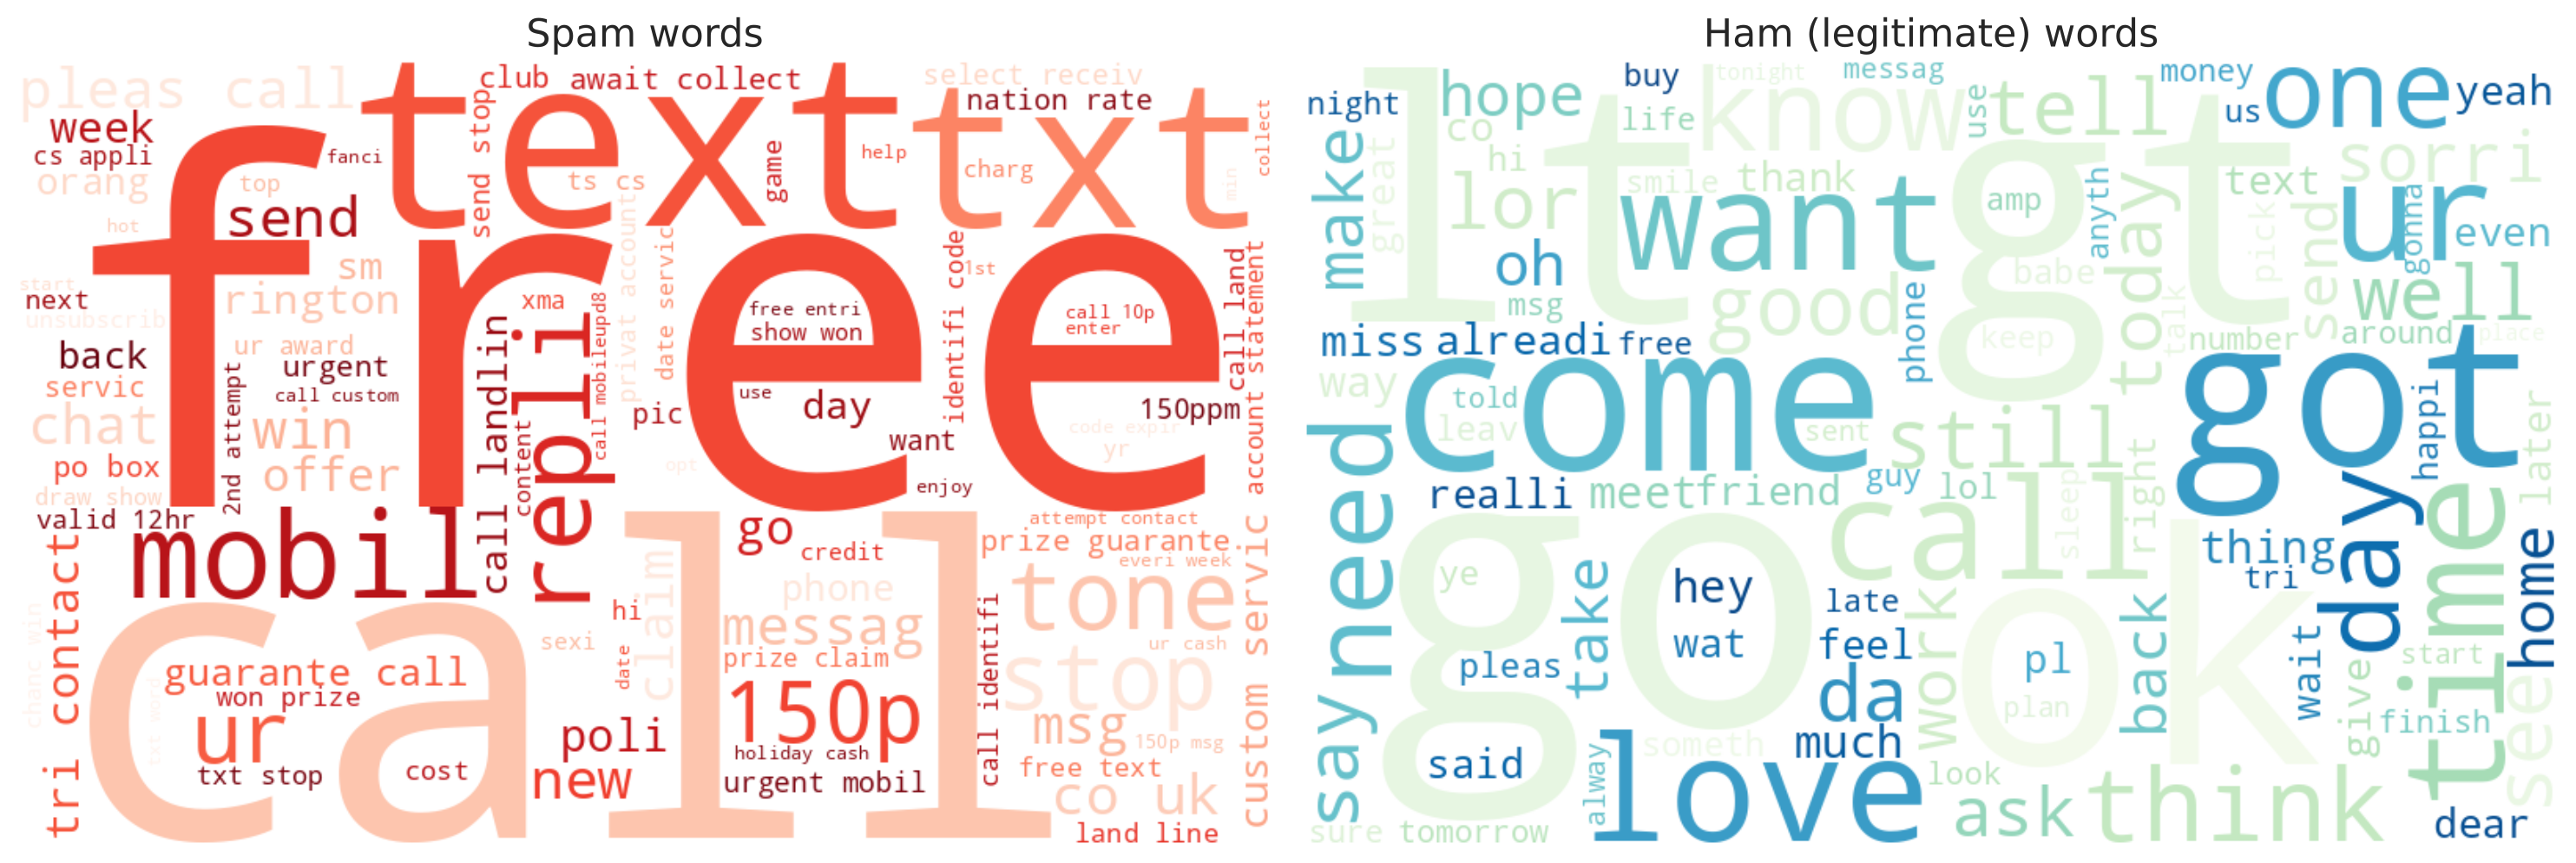

In [ ]:
# Join all spam text and all ham text together
spam_text = " ".join(df[df["label"] == "spam"]["clean"])
ham_text = " ".join(df[df["label"] == "ham"]["clean"])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, text, title, colormap in [
    (axes[0], spam_text, "Spam words", "Reds"),
    (axes[1], ham_text, "Ham (legitimate) words", "GnBu"),
]:
    cloud = WordCloud(width=800, height=500, background_color="white",
                      colormap=colormap, max_words=100, random_state=RANDOM_STATE).generate(text)
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(title, fontsize=16)
    ax.axis("off")
plt.tight_layout()
plt.show()

**What we see:** spam is dominated by calls to action and offers (`call`, `free`, `txt`, `text`, `mobil`, `stop`, `repli`, `claim`, `prize`, `cash`), while ham looks like everyday conversation (`go`, `get`, `come`, `ok`, `know`, `love`, `good`, `day`, `home`). The model picks up on exactly this difference.

Two small things to notice: `call` shows up in both clouds (it only becomes a strong clue in combination with other words), and `gt` / `lt` in the ham cloud are leftovers of web-encoded `>` and `<` symbols (like `&lt;3` for a heart), a good reminder that real data is messy.

## 9. Save the best model for the website

We choose the model with the best F1-score. Instead of saving a heavy Python object, we save just the numbers the model learned (each word's weight) as a small **JSON file**. This lets the website score messages with a few lines of plain Python, with no scikit-learn needed there. That keeps the deployment tiny and fast.

All three models are "linear": each one boils down to *a weight per word plus a bias*. A message's **score** is the bias plus the sum of (word weight × the word's TF-IDF value). A positive score means spam, a negative score means ham, and the further from zero, the more confident the call. (The SVM gives a score rather than a true probability, so the website describes its confidence in words instead of showing a percentage.)

In [ ]:
# Use the model with the best F1-score
best_name = results["F1-score"].idxmax()
best_model = models[best_name]
print("Model used by the website:", best_name)
print(results.loc[best_name].round(4).to_dict())

Model used by the website: Linear SVM
{'Accuracy': 0.9845, 'Precision': 0.9915, 'Recall': 0.8855, 'F1-score': 0.9355}


In [ ]:
# Pull out the learned weights and the bias
if isinstance(best_model, MultinomialNB):
    weights = best_model.feature_log_prob_[1] - best_model.feature_log_prob_[0]
    bias = best_model.class_log_prior_[1] - best_model.class_log_prior_[0]
else:
    weights = best_model.coef_[0]
    bias = best_model.intercept_[0]

vocab = tfidf.vocabulary_
terms = tfidf.get_feature_names_out()
model_json = {
    "model_name": best_name,
    "bias": float(bias),
    # one entry per word: [weight, idf]
    "terms": {t: [round(float(weights[vocab[t]]), 6), round(float(tfidf.idf_[vocab[t]]), 6)]
              for t in terms},
}

# Everything the website's "model insights" panel shows
final_counts = df["label"].value_counts()
model_json["info"] = {
    "dataset_messages": int(len(df)),
    "ham": int(final_counts["ham"]),
    "spam": int(final_counts["spam"]),
    "vocabulary": int(len(terms)),
    "test_messages": int(len(y_test)),
    "metrics": {name: {k: round(float(v), 4) for k, v in row.items()}
                for name, row in results.iterrows()},
    # "gt", "lt" and "didn" are leftovers of web-encoded symbols and broken apostrophes, so we hide them from the display lists
    "top_spam_words": [terms[i] for i in np.argsort(weights)[::-1] if terms[i] not in ("gt", "lt", "didn")][:12],
    "top_ham_words": [terms[i] for i in np.argsort(weights) if terms[i] not in ("gt", "lt", "didn")][:12],
}

# How the chosen model did on the test messages, in plain counts
tn, fp, fn, tp = confusion_matrix(y_test, predictions[best_name]).ravel()
model_json["info"]["test_confusion"] = {
    "spam_caught": int(tp), "spam_missed": int(fn),
    "ham_kept": int(tn), "ham_wrongly_flagged": int(fp),
}

with open("model/model.json", "w") as f:
    json.dump(model_json, f, separators=(",", ":"))

import os
print("Saved model/model.json:", round(os.path.getsize("model/model.json") / 1024), "KB")

Saved model/model.json: 77 KB


In [ ]:
# Safety check: score the test messages using ONLY the saved JSON and plain Python,
# exactly the way the website does, and confirm we get the same answers as scikit-learn.
import math

def score_from_json(clean_message, saved):
    counts = {}
    for word in clean_message.split():
        if word in saved["terms"]:
            counts[word] = counts.get(word, 0) + 1
    tfidf_values = {w: c * saved["terms"][w][1] for w, c in counts.items()}
    length = math.sqrt(sum(v * v for v in tfidf_values.values())) or 1.0
    return saved["bias"] + sum(saved["terms"][w][0] * v / length for w, v in tfidf_values.items())

with open("model/model.json") as f:
    saved = json.load(f)

# Positive score = spam. (For Naive Bayes this is the log-odds, so the cut-off is also 0.)
json_pred = [int(score_from_json(m, saved) > 0) for m in X_test_text]
agree = np.mean(np.array(json_pred) == predictions[best_name])
print(f"JSON model agrees with scikit-learn on {agree:.1%} of test messages")

JSON model agrees with scikit-learn on 100.0% of test messages


## Summary

- The data is imbalanced (about 13% spam), so we judged the models on precision, recall and F1, not just accuracy.
- A simple pipeline of **cleaning → TF-IDF → classifier** separates spam from ham very well.
- All three models score highly, but the **Linear SVM is best** (about 98.5% accuracy, 99% precision, 89% recall, F1 of 0.94). It catches 116 of the 131 spam messages in the test set and wrongly flags just one good message.
- Recall tells us how much spam gets through, precision tells us how many good messages are wrongly blocked, and a good filter needs both.

**Limits worth remembering:** this dataset is SMS from around 2005, so modern spam (new scam wording, other languages, image-based spam) can look different. A real system would retrain regularly on fresh data.